# Beginner findings 12-17: space weather

Section D was not explored step by step in its own notebook (the background builder stopped on a network error),
so the numbers each finding needs are computed here straight from the data file and saved to `numbers/BF12...csv`
to `numbers/BF17...csv`, with a chart for each finding. Times are UTC unless a cell says Toronto.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import helpers as hp
import simple_charts as kc
from bf_tools import Facts, Meet, n0, d, p, g

hp.chart_style()
sw = hp.read_csv("space_weather", usecols=["datetime_utc", "sym_h_nT", "bz_gsm_nT", "speed_km_s", "density_cm3", "pressure_nPa"])
sw.index = pd.to_datetime(sw.pop("datetime_utc"), format="%Y-%m-%d %H:%M")
symh = sw["sym_h_nT"]
last_symh = symh.last_valid_index()
print(f"{len(sw):,} rows, {sw.index.min()} to {sw.index.max()}; sym_h_nT ends {last_symh}")

# storm events: runs of readings <= -50, joined when less than 12 hours apart
below = symh.le(-50)
tb = symh.index[below.to_numpy()]
brk = np.r_[True, np.asarray(np.diff(tb) > pd.Timedelta("5min"))]  # true time gaps (pandas 3 timestamps are microseconds)
run_start = tb[brk]
run_end = tb[np.r_[brk[1:], True]]
ev = []
s0, e0 = run_start[0], run_end[0]
for s1, e1 in zip(run_start[1:], run_end[1:]):
    # each reading covers 5 minutes, so a run ends 5 minutes after its last timestamp:
    # "less than 12 hours apart" = next start minus last timestamp < 12 h 5 min
    if s1 - e0 < pd.Timedelta("12h5min"):
        e0 = e1
    else:
        ev.append((s0, e0)); s0, e0 = s1, e1
ev.append((s0, e0))
rows = []
for s_, e_ in ev:
    seg = symh[s_:e_]
    rows.append({"start": s_, "end": e_, "low": seg.min(), "low_time": seg.idxmin()})
events = pd.DataFrame(rows)


def n_events(rule):
    """Count events under a slightly different joining rule (for the comparison with the Field Guide)."""
    k_, e_last = 1, run_end[0]
    for s1, e1 in zip(run_start[1:], run_end[1:]):
        if not rule(s1 - e_last):
            k_ += 1
        e_last = e1
    return k_


n_raw_runs = len(run_start)
print(f"events: {len(events)}; <= -100: {(events.low <= -100).sum()}; <= -200: {(events.low <= -200).sum()}; <= -250: {(events.low <= -250).sum()}")

1,766,880 rows, 2010-01-01 00:00:00 to 2026-10-18 23:55:00; sym_h_nT ends 2026-09-30 23:55:00
events: 442; <= -100: 71; <= -200: 10; <= -250: 4


## Finding 12: storms follow the Sun's 11-year cycle, and this cycle is stronger

                key        value       shown   unit                         source
0         storm_cut   -50.000000         -50     nT                   rule we used
1        strong_cut  -100.000000        -100     nT                   rule we used
2              days  6117.000000       6,117                              our data
3        storm_2015    69.000000          69                              our data
4       strong_2015    12.000000          12                              our data
5        storm_2019    11.000000          11                              our data
6       strong_2019     0.000000           0                              our data
7        storm_2020     9.000000           9                              our data
8       strong_2020     0.000000           0                              our data
9        storm_2024    66.000000          66                              our data
10      strong_2024    21.000000          21                              our data
11  

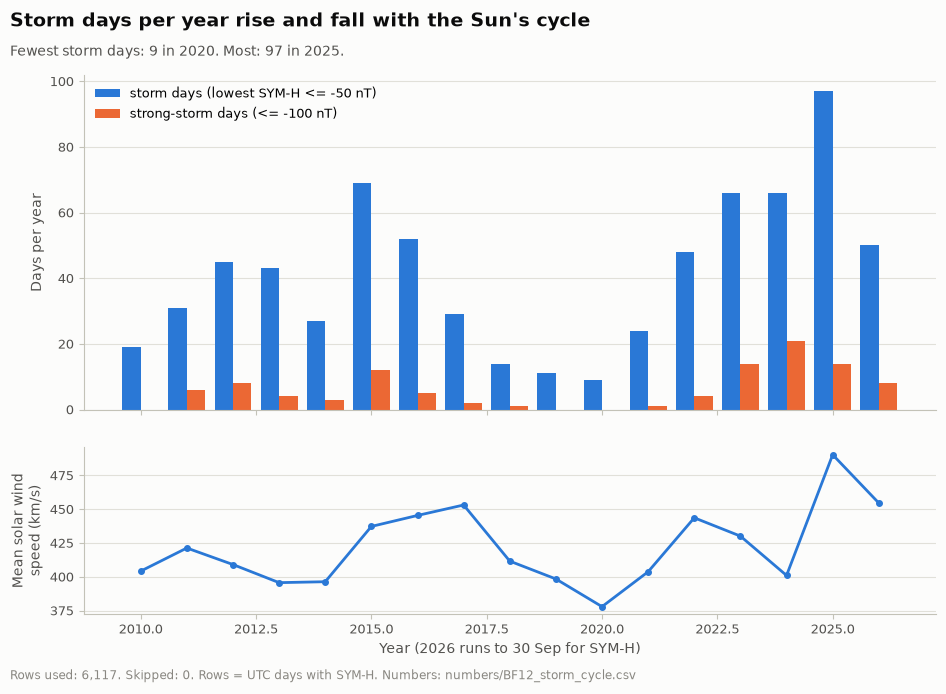

In [2]:
F = Facts(12, "storm_cycle")
day_min = symh[:last_symh].resample("D").min()
storm = (day_min <= -50).groupby(day_min.index.year).sum()
strong = (day_min <= -100).groupby(day_min.index.year).sum()
F.rule("storm_cut", -50, "-50", "nT"); F.rule("strong_cut", -100, "-100", "nT")
F.add("days", int(day_min.notna().sum()))
for y_ in (2015, 2019, 2020, 2024, 2025):
    F.add(f"storm_{y_}", int(storm[y_])); F.add(f"strong_{y_}", int(strong[y_]))
F.add("storm_max_year", int(storm.idxmax()), str(int(storm.idxmax()))); F.add("storm_max", int(storm.max()))
F.add("strong_max_year", int(strong.idxmax()), str(int(strong.idxmax()))); F.add("strong_max", int(strong.max()))
F.add("storm_min_year", int(storm.idxmin()), str(int(storm.idxmin()))); F.add("storm_min", int(storm.min()))
F.add("last_day", 0, last_symh.strftime("%Y-%m-%d"), source="our data (date)")
spd = sw["speed_km_s"].groupby(sw.index.year).mean()
F.add("speed_max_year", int(spd.idxmax()), str(int(spd.idxmax()))); F.add("speed_max", spd.max(), n0(spd.max()), "km/s")
F.add("speed_min_year", int(spd.idxmin()), str(int(spd.idxmin()))); F.add("speed_min", spd.min(), n0(spd.min()), "km/s")
F.add("ex_day", 0, day_min.idxmin().strftime("%Y-%m-%d"), source="our data (date)"); F.add("ex_day_min", day_min.min(), n0(day_min.min()), "nT")
F.outside("cycle_years", 11, "11", "years", source="known science (sunspot cycle)")
for y_ in (2019, 2020, 2024, 2025, 2026):
    F.rule(f"y_{y_}", y_, str(y_))
F.add("ex_speed", sw["speed_km_s"][day_min.idxmin():day_min.idxmin() + pd.Timedelta("1D") - pd.Timedelta("5min")].mean(), n0(sw["speed_km_s"][day_min.idxmin():day_min.idxmin() + pd.Timedelta("1D") - pd.Timedelta("5min")].mean()), "km/s")
print(F.table().to_string()); f12 = F.save()
fig, axs = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1], "hspace": 0.15})
yy = storm.index.to_numpy()
axs[0].bar(yy - 0.2, storm.values, width=0.4, color=hp.SERIES[0], label="storm days (lowest SYM-H <= -50 nT)")
axs[0].bar(yy + 0.2, strong.values, width=0.4, color=hp.SERIES[1], label="strong-storm days (<= -100 nT)")
axs[0].set_ylabel("Days per year"); axs[0].legend(loc="upper left")
axs[1].plot(spd.index, spd.values, color=hp.SERIES[0], marker="o", ms=4)
axs[1].set_ylabel("Mean solar wind\nspeed (km/s)"); axs[1].set_xlabel("Year (2026 runs to 30 Sep for SYM-H)")
for ax in axs:
    ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Storm days per year rise and fall with the Sun's cycle",
              f"Fewest storm days: {int(storm.min())} in {int(storm.idxmin())}. Most: {int(storm.max())} in {int(storm.idxmax())}.",
              hp.caption(int(day_min.notna().sum()), 0, numbers_file="numbers/BF12_storm_cycle.csv", extra="Rows = UTC days with SYM-H."))
c12 = hp.save_chart(fig, "BF12_storm_days_per_year"); plt.show()
hp.log_entry("D-BF12", "Beginner finding 12 chart: storm days per year and yearly mean speed", step=6, chart=c12, numbers=f12,
             rows_used=f"{int(day_min.notna().sum()):,} days", rows_skipped="0",
             key_numbers=[f"2019 {storm[2019]}, 2020 {storm[2020]}, 2025 {storm[2025]} storm days; strong-storm max {strong.max()} in {strong.idxmax()}"],
             what_it_shows="Storm days fall to a low around 2019-2020 and climb to a peak in 2025.")

## Finding 13: what the solar wind does in the hours before a big storm

                  key        value  shown     unit        source
0          events_all   442.000000    442               our data
1       events_strong    71.000000     71               our data
2          join_gap_h    12.000000     12    hours  rule we used
3          events_200    10.000000     10               our data
4          events_250     4.000000      4               our data
5            raw_runs  1751.000000  1,751               our data
6   events_strict_12h   446.000000    446               our data
7        guide_events   442.000000    442            Field Guide
8            den_base     5.127552    5.1  per cm3      our data
9             den_m20     9.990000   10.0  per cm3      our data
10             den_m8    12.380000   12.4  per cm3      our data
11           pre_base     1.627897    1.6      nPa      our data
12             pre_m8     5.245000    5.2      nPa      our data
13       pre_ratio_m8     3.221949    3.2               our data
14            den_m24    

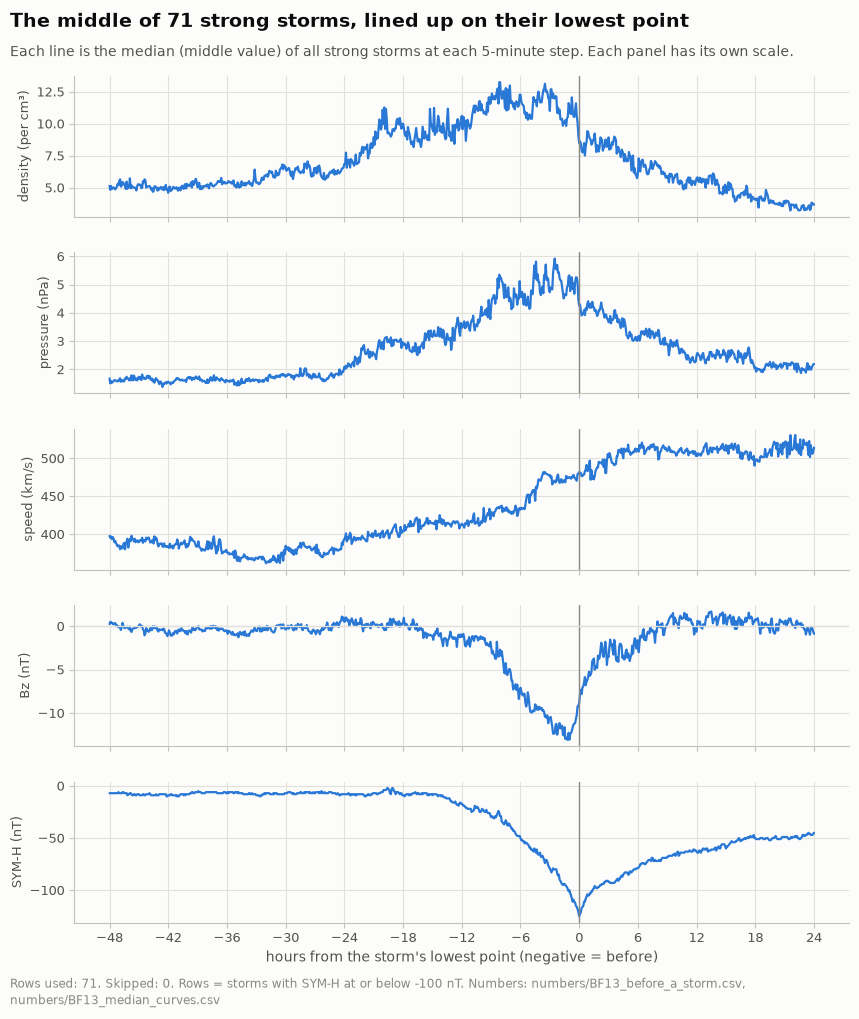

In [3]:
F = Facts(13, "before_a_storm")
big = events[events["low"] <= -100].reset_index(drop=True)
F.add("events_all", len(events)); F.add("events_strong", len(big)); F.rule("join_gap_h", 12, "12", "hours")
F.add("events_200", int((events.low <= -200).sum())); F.add("events_250", int((events.low <= -250).sum()))
F.add("raw_runs", n_raw_runs)
F.add("events_strict_12h", n_events(lambda gap: gap < pd.Timedelta("12h")))
F.outside("guide_events", 442, "442", source="Field Guide")
offs = np.arange(-576, 289)  # 5-minute steps from -48 h to +24 h
VARS = ["sym_h_nT", "bz_gsm_nT", "speed_km_s", "density_cm3", "pressure_nPa"]
grid = sw[VARS].reindex(pd.date_range(sw.index.min(), sw.index.max(), freq="5min"))
pos = grid.index.get_indexer(big["low_time"])
med = {}
for v in VARS:
    arr = grid[v].to_numpy()
    M = np.full((len(big), len(offs)), np.nan)
    for k_, p0 in enumerate(pos):
        lo_, hi_ = p0 + offs[0], p0 + offs[-1] + 1
        if lo_ >= 0 and hi_ <= len(arr):
            M[k_] = arr[lo_:hi_]
    med[v] = np.nanmedian(M, axis=0)
hrs = offs * 5 / 60
at = lambda v, h: float(med[v][np.searchsorted(hrs, h)])  # noqa: E731
base_den, base_pre = float(np.nanmean(med["density_cm3"][hrs <= -36])), float(np.nanmean(med["pressure_nPa"][hrs <= -36]))
F.add("den_base", base_den, d(base_den, 1), "per cm3"); F.add("den_m20", at("density_cm3", -20), d(at("density_cm3", -20), 1), "per cm3")
F.add("den_m8", at("density_cm3", -8), d(at("density_cm3", -8), 1), "per cm3")
F.add("pre_base", base_pre, d(base_pre, 1), "nPa"); F.add("pre_m8", at("pressure_nPa", -8), d(at("pressure_nPa", -8), 1), "nPa")
F.add("pre_ratio_m8", at("pressure_nPa", -8) / base_pre, d(at("pressure_nPa", -8) / base_pre, 1))
F.add("den_m24", at("density_cm3", -24), d(at("density_cm3", -24), 1), "per cm3"); F.add("pre_m24", at("pressure_nPa", -24), d(at("pressure_nPa", -24), 1), "nPa")
for h in (-24, -8, -6, -2, 0):
    F.add(f"bz_{abs(h)}", at("bz_gsm_nT", h), d(at("bz_gsm_nT", h), 1), "nT")
    F.add(f"symh_{abs(h)}", at("sym_h_nT", h), n0(at("sym_h_nT", h)), "nT")
F.add("speed_m24", at("speed_km_s", -24), n0(at("speed_km_s", -24)), "km/s"); F.add("speed_0", at("speed_km_s", 0), n0(at("speed_km_s", 0)), "km/s")
# storm by storm: hours from the first Bz <= -10 nT (in the 24 h before the lowest point) to the lowest point
lead = []
bzs = sw["bz_gsm_nT"]
for t_low in big["low_time"]:
    seg = bzs[t_low - pd.Timedelta("24h"):t_low]
    hit = seg[seg <= -10]
    if len(hit):
        lead.append((t_low - hit.index[0]).total_seconds() / 3600)
lead = np.array(lead)
F.rule("bz_cut", -10, "-10", "nT")
F.add("lead_n", len(lead)); F.add("lead_median", np.median(lead), d(np.median(lead), 1), "hours")
F.add("lead_q1", np.percentile(lead, 25), d(np.percentile(lead, 25), 1), "hours"); F.add("lead_q3", np.percentile(lead, 75), d(np.percentile(lead, 75), 1), "hours")
lead48 = []
for t_low in big["low_time"]:
    seg = bzs[t_low - pd.Timedelta("48h"):t_low]
    hit = seg[seg <= -10]
    if len(hit):
        lead48.append((t_low - hit.index[0]).total_seconds() / 3600)
F.add("lead48_median", np.median(lead48), d(np.median(lead48), 1), "hours")
F.rule("step_min", 5, "5", "minutes"); F.rule("h20", 20, "20", "hours"); F.rule("h8", 8, "8", "hours"); F.rule("h6", 6, "6", "hours"); F.rule("h2", 2, "2", "hours")
F.rule("h48", 48, "48", "hours"); F.rule("h36", 36, "36", "hours"); F.rule("h24", 24, "24", "hours")
F.rule("storm_cut", -50, "-50", "nT"); F.rule("strong_cut", -100, "-100", "nT")
print(F.table().to_string()); f13 = F.save()
pd.DataFrame({"hours_from_lowest": hrs, **{v: med[v] for v in VARS}}).to_csv(hp.NUMBERS / "BF13_median_curves.csv", index=False)
fig, axs = plt.subplots(5, 1, figsize=(10, 11), sharex=True, gridspec_kw={"hspace": 0.25})
labels = {"sym_h_nT": "SYM-H (nT)", "bz_gsm_nT": "Bz (nT)", "speed_km_s": "speed (km/s)", "density_cm3": "density (per cm³)", "pressure_nPa": "pressure (nPa)"}
for ax, v in zip(axs, ["density_cm3", "pressure_nPa", "speed_km_s", "bz_gsm_nT", "sym_h_nT"]):
    ax.plot(hrs, med[v], color=hp.SERIES[0], lw=1.6)
    ax.axvline(0, color=hp.INK_MUTED, lw=1); ax.set_ylabel(labels[v], fontsize=9)
    if v == "bz_gsm_nT":
        ax.axhline(0, color=hp.GRID, lw=1)
axs[-1].set_xlabel("hours from the storm's lowest point (negative = before)")
axs[-1].set_xticks(range(-48, 25, 6))
hp.add_titles(fig, f"The middle of {len(big)} strong storms, lined up on their lowest point",
              "Each line is the median (middle value) of all strong storms at each 5-minute step. Each panel has its own scale.",
              hp.caption(len(big), 0, numbers_file="numbers/BF13_before_a_storm.csv, numbers/BF13_median_curves.csv",
                         extra="Rows = storms with SYM-H at or below -100 nT."))
c13 = hp.save_chart(fig, "BF13_before_a_storm"); plt.show()
hp.log_entry("D-BF13", "Beginner finding 13 chart: median solar wind before and after strong storms", step=6, chart=c13,
             numbers=[f13, "numbers/BF13_median_curves.csv"], rows_used=f"{len(big)} strong storms", rows_skipped="0",
             key_numbers=[f"events <= -50: {len(events)}; <= -100: {len(big)}", f"Bz median -6 h {at('bz_gsm_nT', -6):.1f}, -2 h {at('bz_gsm_nT', -2):.1f}",
                          f"first Bz <= -10 to lowest point: median {np.median(lead):.1f} h"],
             what_it_shows="Before the lowest point, density and pressure rise first, then Bz turns negative and SYM-H drops.")

## Finding 14: the Sun repeats itself every 27 days

          key        value       shown  unit                                             source
0        days  6115.000000       6,115                                                 our data
1      all_13     0.078271        0.08                                                 our data
2      sub_13     0.088454        0.09                                                 our data
3      all_20     0.036651        0.04                                                 our data
4      sub_20    -0.096434       -0.10                                                 our data
5      all_27     0.455036        0.46                                                 our data
6      sub_27     0.599592        0.60                                                 our data
7    best_lag    27.000000          27  days                                           our data
8     ex_day1     0.000000  2010-04-11                                          our data (date)
9   ex_speed1   402.971368         403  

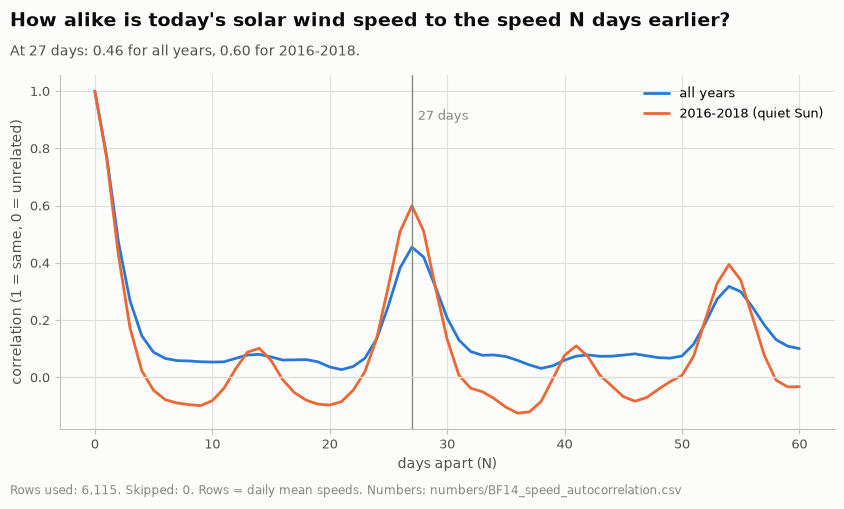

In [4]:
F = Facts(14, "repeats_27_days")
dsp = sw["speed_km_s"].resample("D").mean()
def acf(s, lag):
    return s.corr(s.shift(lag))
lags = range(0, 61)
all_ = [acf(dsp, k_) for k_ in lags]
sub = dsp["2016":"2018"]
sub_ = [acf(sub, k_) for k_ in lags]
F.add("days", int(dsp.notna().sum()))
for k_ in (13, 20, 27):
    F.add(f"all_{k_}", all_[k_], d(all_[k_], 2)); F.add(f"sub_{k_}", sub_[k_], d(sub_[k_], 2))
best = 20 + int(np.argmax(all_[20:36]))
F.add("best_lag", best, str(best), "days")
F.add("ex_day1", 0, dsp.index[100].strftime("%Y-%m-%d"), source="our data (date)"); F.add("ex_speed1", dsp.iloc[100], n0(dsp.iloc[100]), "km/s")
F.add("ex_day2", 0, dsp.index[127].strftime("%Y-%m-%d"), source="our data (date)"); F.add("ex_speed2", dsp.iloc[127], n0(dsp.iloc[127]), "km/s")
F.outside("sun_turn", 27, "27", "days", source="known science (the Sun's turn as seen from Earth)")
F.rule("lag13", 13, "13", "days"); F.rule("lag20", 20, "20", "days"); F.rule("lag35", 35, "35", "days")
F.rule("y_2016", 2016, "2016"); F.rule("y_2018", 2018, "2018"); F.rule("lag60", 60, "60", "days"); F.rule("y_2017", 2017, "2017")
print(F.table().to_string()); f14 = F.save()
pd.DataFrame({"lag_days": list(lags), "corr_all_years": all_, "corr_2016_2018": sub_}).to_csv(hp.NUMBERS / "BF14_speed_autocorrelation.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(list(lags), all_, color=hp.SERIES[0], label="all years")
ax.plot(list(lags), sub_, color=hp.SERIES[1], label="2016-2018 (quiet Sun)")
ax.axvline(27, color=hp.INK_MUTED, lw=1); ax.axhline(0, color=hp.GRID, lw=1)
ax.text(27.5, 0.9, "27 days", fontsize=9, color=hp.INK_MUTED)
ax.set_xlabel("days apart (N)"); ax.set_ylabel("correlation (1 = same, 0 = unrelated)"); ax.legend()
hp.add_titles(fig, "How alike is today's solar wind speed to the speed N days earlier?",
              f"At 27 days: {all_[27]:.2f} for all years, {sub_[27]:.2f} for 2016-2018.",
              hp.caption(int(dsp.notna().sum()), 0, numbers_file="numbers/BF14_speed_autocorrelation.csv", extra="Rows = daily mean speeds."))
c14 = hp.save_chart(fig, "BF14_27_day_repeat"); plt.show()
hp.log_entry("D-BF14", "Beginner finding 14 chart: correlation of daily speed with N days earlier", step=6, chart=c14,
             numbers=[f14, "numbers/BF14_speed_autocorrelation.csv"], rows_used=f"{int(dsp.notna().sum()):,} days", rows_skipped="0",
             key_numbers=[f"lag 27: {all_[27]:.2f} (all), {sub_[27]:.2f} (2016-2018)", f"lag 13: {all_[13]:.2f}; lag 20: {all_[20]:.2f}"],
             what_it_shows="Solar wind speed looks most like the speed 27 days earlier.")

## Finding 15: storms prefer the equinoxes

              key         value      shown unit            source
0         share_1  2.709256e+00       2.7%               our data
1        strong_1  6.000000e+00          6               our data
2         share_2  1.955295e+00       2.0%               our data
3        strong_2  3.000000e+00          3               our data
4         share_3  4.535631e+00       4.5%               our data
5        strong_3  1.000000e+01         10               our data
6         share_4  4.170071e+00       4.2%               our data
7        strong_4  6.000000e+00          6               our data
8         share_5  3.611902e+00       3.6%               our data
9        strong_5  5.000000e+00          5               our data
10        share_6  2.613017e+00       2.6%               our data
11       strong_6  7.000000e+00          7               our data
12        share_7  1.954196e+00       2.0%               our data
13       strong_7  2.000000e+00          2               our data
14        

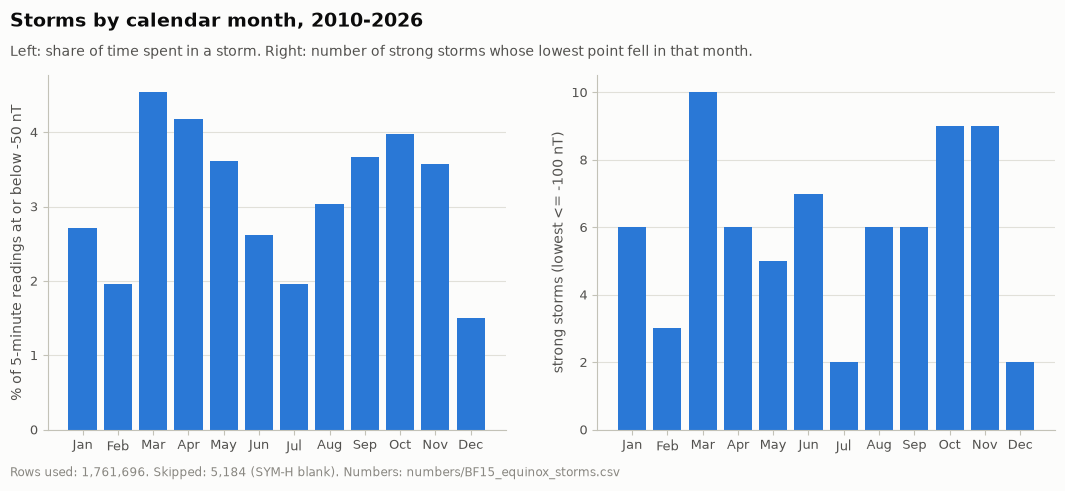

In [5]:
F = Facts(15, "equinox_storms")
ok = symh.notna()
share = 100 * symh[ok].le(-50).groupby(symh[ok].index.month).mean()
strong_m = big["low_time"].dt.month.value_counts().reindex(range(1, 13), fill_value=0)
MON = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
for m_ in range(1, 13):
    F.add(f"share_{m_}", share[m_], p(share[m_], 1)); F.add(f"strong_{m_}", int(strong_m[m_]))
F.add("readings", int(ok.sum())); F.add("strong_total", int(strong_m.sum()))
F.add("max_month", 0, MON[int(share.idxmax()) - 1], source="our data (month)"); F.add("min_month", 0, MON[int(share.idxmin()) - 1], source="our data (month)")
F.add("max_vs_min", share.max() / share.min(), d(share.max() / share.min(), 1))
F.outside("guide_sep_oct", 3.75, "3.7-3.8%", source="Field Guide")
F.rule("storm_cut", -50, "-50", "nT"); F.rule("strong_cut", -100, "-100", "nT")
print(F.table().to_string()); f15 = F.save()
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
axs[0].bar(MON, share.values, color=hp.SERIES[0]); axs[0].set_ylabel("% of 5-minute readings at or below -50 nT")
axs[1].bar(MON, strong_m.values, color=hp.SERIES[0]); axs[1].set_ylabel("strong storms (lowest <= -100 nT)")
for ax in axs:
    ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Storms by calendar month, 2010-2026",
              "Left: share of time spent in a storm. Right: number of strong storms whose lowest point fell in that month.",
              hp.caption(int(ok.sum()), int((~ok).sum()), "SYM-H blank", "numbers/BF15_equinox_storms.csv"))
c15 = hp.save_chart(fig, "BF15_storms_by_month"); plt.show()
hp.log_entry("D-BF15", "Beginner finding 15 chart: storm share and strong storms by month", step=6, chart=c15, numbers=f15,
             rows_used=int(ok.sum()), rows_skipped=f"{int((~ok).sum()):,} (SYM-H blank)",
             key_numbers=[f"March {share[3]:.1f}%, December {share[12]:.1f}%", f"strong storms March {strong_m[3]}, July {strong_m[7]}"],
             what_it_shows="Storm time peaks in March-April and September-October and dips in June-July and December.")

## Finding 16: the May 2024 superstorm, hour by hour

                   key        value              shown     unit           source
0            shock_utc     0.000000              17:05           our data (time)
1            shock_tor     0.000000              13:05           our data (time)
2         speed_before   447.400000                447     km/s         our data
3          speed_after   608.200000                608     km/s         our data
4           den_before    14.880000               14.9  per cm3         our data
5            den_after    35.130000               35.1  per cm3         our data
6            den_ratio     2.360887                2.4                  our data
7              symh_up    79.000000                +79       nT         our data
8             bz_step1   -15.000000                -15       nT     rule we used
9             bz_step2   -30.000000                -30       nT     rule we used
10                 bz1   -16.280000                -16       nT         our data
11             bz1_utc     0

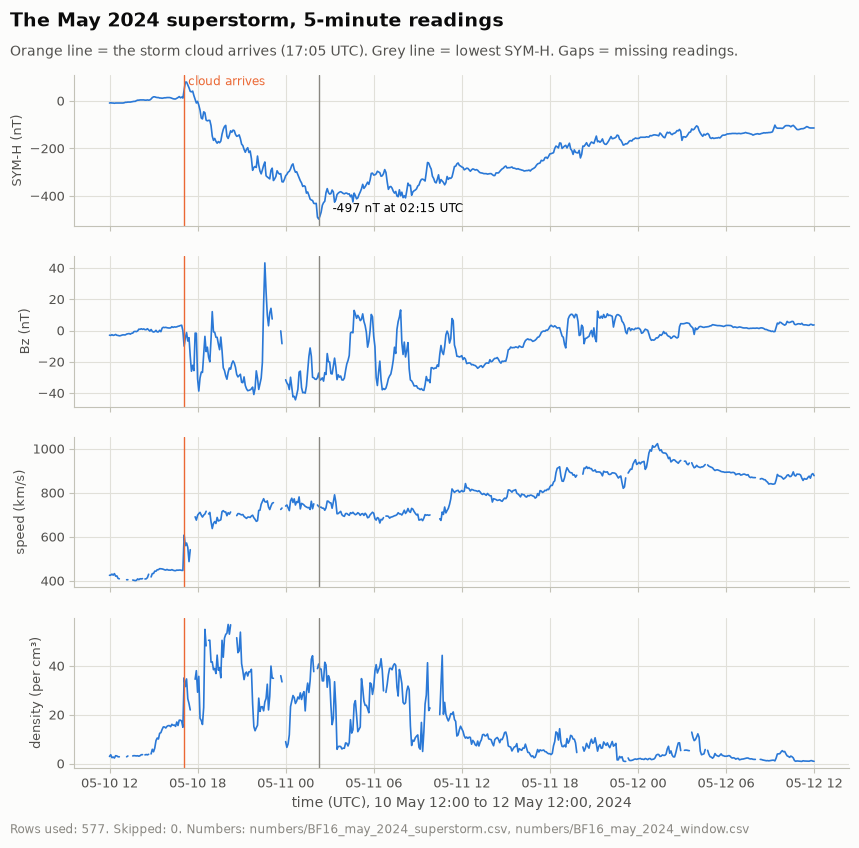

In [6]:
F = Facts(16, "may_2024_superstorm")
w = sw["2024-05-10 12:00":"2024-05-12 12:00"]
sp = w["speed_km_s"]
jump = sp.diff()
t_shock = jump["2024-05-10 15:00":"2024-05-10 20:00"].idxmax()
before = sp[:t_shock].iloc[:-1].dropna().iloc[-1]
after = sp[t_shock]
den_b = w["density_cm3"][:t_shock].iloc[:-1].dropna().iloc[-1]
den_a = w["density_cm3"][t_shock]
TOR = "America/Toronto"
to_tor = lambda t: t.tz_localize("UTC").tz_convert(TOR)  # noqa: E731
F.add("shock_utc", 0, t_shock.strftime("%H:%M"), source="our data (time)"); F.add("shock_tor", 0, to_tor(t_shock).strftime("%H:%M"), source="our data (time)")
F.add("speed_before", before, n0(before), "km/s"); F.add("speed_after", after, n0(after), "km/s")
F.add("den_before", den_b, d(den_b, 1), "per cm3"); F.add("den_after", den_a, d(den_a, 1), "per cm3"); F.add("den_ratio", den_a / den_b, d(den_a / den_b, 1))
sh_up = w["sym_h_nT"][t_shock:t_shock + pd.Timedelta("2h")].max()
F.add("symh_up", sh_up, f"+{sh_up:.0f}", "nT")
bzw = w["bz_gsm_nT"][t_shock:]
t15, t30 = bzw[bzw <= -15].index[0], bzw[bzw <= -30].index[0]
F.rule("bz_step1", -15, "-15", "nT"); F.rule("bz_step2", -30, "-30", "nT")
F.add("bz1", bzw[t15], n0(bzw[t15]), "nT"); F.add("bz1_utc", 0, t15.strftime("%H:%M"), source="our data (time)")
F.add("bz1_min_after", (t15 - t_shock).total_seconds() / 60, n0((t15 - t_shock).total_seconds() / 60), "minutes")
F.add("bz2", bzw[t30], n0(bzw[t30]), "nT"); F.add("bz2_utc", 0, t30.strftime("%H:%M"), source="our data (time)")
t_plus10 = t_shock + pd.Timedelta("10min")
F.add("speed_plus10", sp[t_plus10], n0(sp[t_plus10]), "km/s"); F.add("plus10_utc", 0, t_plus10.strftime("%H:%M"), source="our data (time)")
F.outside("guide_speed_after", 572, "572", "km/s", source="Field Guide")
low_t = w["sym_h_nT"].idxmin(); low_v = w["sym_h_nT"].min()
F.add("low", low_v, n0(low_v), "nT"); F.add("low_utc", 0, low_t.strftime("%d %b %H:%M"), source="our data (time)")
F.add("low_tor", 0, to_tor(low_t).strftime("%d %b %H:%M"), source="our data (time)")
F.add("hours_shock_to_low", (low_t - t_shock).total_seconds() / 3600, d((low_t - t_shock).total_seconds() / 3600, 1), "hours")
F.add("bz_min_window", w["bz_gsm_nT"].min(), d(w["bz_gsm_nT"].min(), 1), "nT")
F.add("bz_blank_pct", 100 * w["bz_gsm_nT"].isna().mean(), p(100 * w["bz_gsm_nT"].isna().mean()))
oct_ = symh["2024-10-01":"2024-10-31"]
F.add("oct_low", oct_.min(), n0(oct_.min()), "nT"); F.add("oct_utc", 0, oct_.idxmin().strftime("%d %b %H:%M"), source="our data (time)")
F.add("oct_tor", 0, to_tor(oct_.idxmin()).strftime("%d %b %H:%M"), source="our data (time)")
F.add("file_low", symh.min(), n0(symh.min()), "nT")
F.rule("win_from", 0, "10 May 2024 12:00"); F.rule("win_to", 0, "12 May 2024 12:00")
F.rule("win_from_code", 0, "2024-05-10 12:00"); F.rule("win_to_code", 0, "2024-05-12 12:00")
F.add("win_rows", len(w)); F.outside("guide_shock", 0, "17:10", source="Field Guide")
F.rule("y_2024", 2024, "2024"); F.rule("step_min", 5, "5", "minutes")
print(F.table().to_string()); f16 = F.save()
w.reset_index(names="time_utc").to_csv(hp.NUMBERS / "BF16_may_2024_window.csv", index=False)
fig, axs = plt.subplots(4, 1, figsize=(10, 9), sharex=True, gridspec_kw={"hspace": 0.2})
for ax, v, lab in zip(axs, ["sym_h_nT", "bz_gsm_nT", "speed_km_s", "density_cm3"],
                      ["SYM-H (nT)", "Bz (nT)", "speed (km/s)", "density (per cm³)"]):
    ax.plot(w.index, w[v], color=hp.SERIES[0], lw=1.2); ax.set_ylabel(lab, fontsize=9)
    ax.axvline(t_shock, color=hp.SERIES[1], lw=1); ax.axvline(low_t, color=hp.INK_MUTED, lw=1)
axs[0].annotate(f"{low_v:.0f} nT at {low_t:%H:%M} UTC", (low_t, low_v), xytext=(10, 5), textcoords="offset points", fontsize=8.5)
axs[0].text(t_shock, axs[0].get_ylim()[1], " cloud arrives", fontsize=8.5, color=hp.SERIES[1], va="top")
axs[-1].set_xlabel("time (UTC), 10 May 12:00 to 12 May 12:00, 2024")
hp.add_titles(fig, "The May 2024 superstorm, 5-minute readings",
              f"Orange line = the storm cloud arrives ({t_shock:%H:%M} UTC). Grey line = lowest SYM-H. Gaps = missing readings.",
              hp.caption(len(w), 0, numbers_file="numbers/BF16_may_2024_superstorm.csv, numbers/BF16_may_2024_window.csv"))
c16 = hp.save_chart(fig, "BF16_may_2024"); plt.show()
hp.log_entry("D-BF16", "Beginner finding 16 chart: May 2024 superstorm hour by hour", step=6, chart=c16,
             numbers=[f16, "numbers/BF16_may_2024_window.csv"], rows_used=len(w), rows_skipped="0 (gaps shown as gaps)",
             key_numbers=[f"cloud arrives {t_shock:%H:%M} UTC; speed {before:.0f} -> {after:.0f} km/s", f"lowest {low_v:.0f} nT at {low_t:%d %b %H:%M} UTC"],
             what_it_shows="Speed and density jump when the cloud arrives; SYM-H reaches the file's lowest value about 9 hours later.")

## Finding 17: big storms that peaked during an Ontario night

                  key   value         shown   unit           source
0              from_h    21.0         21:00            rule we used
1                to_h     4.0         04:00            rule we used
2                 cut  -100.0          -100     nT     rule we used
3        nights_total    58.0            58                our data
4          nights_all  6117.0         6,117                our data
5              n_2019     0.0             0                our data
6              n_2020     0.0             0                our data
7              n_2022     0.0             0                our data
8              n_2023     9.0             9                our data
9              n_2024     9.0             9                our data
10             n_2025     9.0             9                our data
11         max_year_n     9.0             9                our data
12            jan_low  -251.0          -251     nT         our data
13            jan_utc     0.0  20 Jan 11:50     

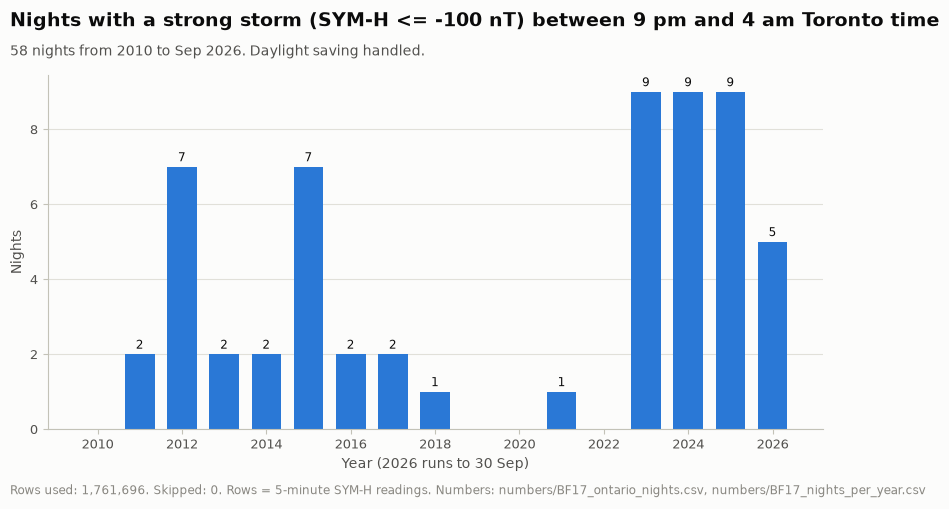

In [7]:
F = Facts(17, "ontario_nights")
s = symh[:last_symh].dropna()
loc_t = s.index.tz_localize("UTC").tz_convert("America/Toronto")
hr = loc_t.hour
dark = (hr >= 21) | (hr < 4)
night = pd.Series(loc_t.normalize().tz_localize(None), index=s.index)
night[hr < 4] = night[hr < 4] - pd.Timedelta("1D")
dmin = s[dark].groupby(night[dark]).min()
good = dmin[dmin <= -100]
per_y = good.groupby(good.index.year).size().reindex(range(2010, 2027), fill_value=0)
F.rule("from_h", 21, "21:00"); F.rule("to_h", 4, "04:00"); F.rule("cut", -100, "-100", "nT")
F.add("nights_total", len(good)); F.add("nights_all", len(dmin))
for y_ in (2019, 2020, 2022, 2023, 2024, 2025):
    F.add(f"n_{y_}", int(per_y[y_]))
F.add("max_year_n", int(per_y.max()))
jan = symh["2026-01-01":"2026-01-31"]
jt = jan.idxmin()
F.add("jan_low", jan.min(), n0(jan.min()), "nT"); F.add("jan_utc", 0, jt.strftime("%d %b %H:%M"), source="our data (time)")
F.add("jan_tor", 0, jt.tz_localize("UTC").tz_convert("America/Toronto").strftime("%H:%M"), source="our data (time)")
jn = night[jt] if hr[s.index.get_loc(jt)] < 4 or hr[s.index.get_loc(jt)] >= 21 else (pd.Timestamp(jt.tz_localize("UTC").tz_convert("America/Toronto").date()) - pd.Timedelta("1D"))
F.add("jan_dark_before", dmin.get(jn, np.nan), n0(dmin.get(jn, np.nan)), "nT")
F.add("jan_dark_after", dmin.get(jn + pd.Timedelta("1D"), np.nan), n0(dmin.get(jn + pd.Timedelta("1D"), np.nan)), "nT")
F.add("utc_offset_winter", -5, "5", "hours"); F.add("utc_offset_summer", -4, "4", "hours")
F.outside("guide_jan_dark", -167, "-167", "nT", source="Field Guide")
for y_ in (2010, 2019, 2020, 2022, 2023, 2024, 2025, 2026):
    F.rule(f"y_{y_}", y_, str(y_))
F.add("jan_tor_ampm", 0, jt.tz_localize("UTC").tz_convert("America/Toronto").strftime("%-I:%M am"), source="our data (time)")
print(F.table().to_string()); f17 = F.save()
per_y.rename_axis("year").reset_index(name="nights").to_csv(hp.NUMBERS / "BF17_nights_per_year.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(per_y.index, per_y.values, color=hp.SERIES[0], width=0.7)
for x_, v_ in per_y.items():
    if v_:
        ax.text(x_, v_ + 0.15, str(v_), ha="center", fontsize=8.5, color=hp.INK)
ax.set_xlabel("Year (2026 runs to 30 Sep)"); ax.set_ylabel("Nights"); ax.grid(axis="x", visible=False)
ax.set_xticks(range(2010, 2027, 2))
hp.add_titles(fig, "Nights with a strong storm (SYM-H <= -100 nT) between 9 pm and 4 am Toronto time",
              f"{len(good)} nights from 2010 to Sep 2026. Daylight saving handled.",
              hp.caption(len(s), 0, numbers_file="numbers/BF17_ontario_nights.csv, numbers/BF17_nights_per_year.csv",
                         extra="Rows = 5-minute SYM-H readings."))
c17 = hp.save_chart(fig, "BF17_ontario_nights"); plt.show()
hp.log_entry("D-BF17", "Beginner finding 17 chart: strong-storm nights per year in Toronto's dark hours", step=6, chart=c17,
             numbers=[f17, "numbers/BF17_nights_per_year.csv"], rows_used=len(s), rows_skipped="0",
             key_numbers=[f"{len(good)} nights", "per year: " + ", ".join(f"{y_} {v_}" for y_, v_ in per_y.items())],
             what_it_shows="Strong-storm nights cluster in 2023-2025 and are absent in 2019, 2020 and 2022.")
hp.edge_case("D", "Full Section D notebook not built (background builder stopped on a network error); beginner findings 12-17 were computed in notebooks/BF_D_space_weather.ipynb.")

## Plain version: "Meet the data" numbers and one plain chart per finding

Numbers for part D's "Meet the data" text: `numbers/BM_D_meet_space_weather.csv`. New plain charts
`charts/K12_...png` to `charts/K17_...png` (plotted numbers in `numbers/K12_...csv` ...), drawn with `simple_charts`.

In [8]:
kc.plain_style()
M = Meet("D", "meet_space_weather")
M.add("rows_total", len(sw)); M.add("n_columns", len(hp.columns("space_weather")))
M.add("first", 0, sw.index.min().strftime("%Y-%m-%d %H:%M"), source="our data (date and time)")
M.add("last", 0, sw.index.max().strftime("%Y-%m-%d %H:%M"), source="our data (date and time)")
M.add("symh_last", 0, last_symh.strftime("%Y-%m-%d"), source="our data (date)")
M.rule("step_min", 5, "5", "minutes"); M.add("per_day", 24 * 60 / 5, "288", source="rule we used (minutes in a day ÷ 5)")
M.add("per_year", 365 * 24 * 60 / 5, n0(365 * 24 * 60 / 5), source="rule we used (5-minute steps in a year)")
yrs_ = (sw.index.max() - sw.index.min()).days / 365.25
M.add("years_span", yrs_, n0(yrs_), "years")
M.rule("storm_cut", -50, "-50", "nT"); M.rule("strong_cut", -100, "-100", "nT"); M.rule("extreme_cut", -250, "-250", "nT")
for col_, key_ in [("sym_h_nT", "symh"), ("bz_gsm_nT", "bz"), ("speed_km_s", "speed"), ("density_cm3", "den"), ("pressure_nPa", "pre")]:
    M.add(f"{key_}_blank_pct", 100 * sw[col_].isna().mean(), p(100 * sw[col_].isna().mean(), 1))
M.add("speed_median", sw["speed_km_s"].median(), n0(sw["speed_km_s"].median()), "km/s")
M.add("speed_kmh", sw["speed_km_s"].median() * 3600, n0(sw["speed_km_s"].median() * 3600), "km per hour")
M.add("moon_minutes", hp.LD_KM / sw["speed_km_s"].median() / 60, n0(hp.LD_KM / sw["speed_km_s"].median() / 60), "minutes",
      source="our data (Moon distance ÷ middle speed)")
M.add("den_median", sw["density_cm3"].median(), d(sw["density_cm3"].median(), 1), "per cm3")
M.add("pre_median", sw["pressure_nPa"].median(), d(sw["pressure_nPa"].median(), 1), "nPa")
M.add("symh_median", symh.median(), n0(symh.median()), "nT")
M.add("storm_pct", 100 * symh.dropna().le(-50).mean(), p(100 * symh.dropna().le(-50).mean(), 1))
M.add("file_low", symh.min(), n0(symh.min()), "nT"); M.add("file_low_time", 0, symh.idxmin().strftime("%Y-%m-%d %H:%M"), source="our data (date and time)")
calm = sw["2019-06-01":"2019-06-30"].dropna(subset=["sym_h_nT", "bz_gsm_nT", "speed_km_s", "density_cm3", "pressure_nPa"]).iloc[0]
M.add("ex_time", 0, calm.name.strftime("%Y-%m-%d %H:%M"), source="our data (date and time)")
M.add("ex_symh", calm["sym_h_nT"], n0(calm["sym_h_nT"]), "nT"); M.add("ex_bz", calm["bz_gsm_nT"], d(calm["bz_gsm_nT"], 1), "nT")
M.add("ex_speed", calm["speed_km_s"], n0(calm["speed_km_s"]), "km/s"); M.add("ex_den", calm["density_cm3"], d(calm["density_cm3"], 1), "per cm3")
M.add("ex_pre", calm["pressure_nPa"], d(calm["pressure_nPa"], 2), "nPa")
M.add("ex_kmh", calm["speed_km_s"] * 3600, n0(calm["speed_km_s"] * 3600), "km per hour")
M.add("sun_days", hp.AU_KM / sw["speed_km_s"].median() / 86400, d(hp.AU_KM / sw["speed_km_s"].median() / 86400, 1), "days",
      source="our data (1 AU ÷ middle speed, in days)")
M.add("n_other", len(hp.columns("space_weather")) - 6)
print(M.table().to_string()); fmD = M.save()

                key         value             shown         unit                                   source
0        rows_total  1.766880e+06         1,766,880                                              our data
1         n_columns  1.400000e+01                14                                              our data
2             first  0.000000e+00  2010-01-01 00:00                              our data (date and time)
3              last  0.000000e+00  2026-10-18 23:55                              our data (date and time)
4         symh_last  0.000000e+00        2026-09-30                                       our data (date)
5          step_min  5.000000e+00                 5      minutes                             rule we used
6           per_day  2.880000e+02               288                   rule we used (minutes in a day ÷ 5)
7          per_year  1.051200e+05           105,120               rule we used (5-minute steps in a year)
8        years_span  1.679398e+01             

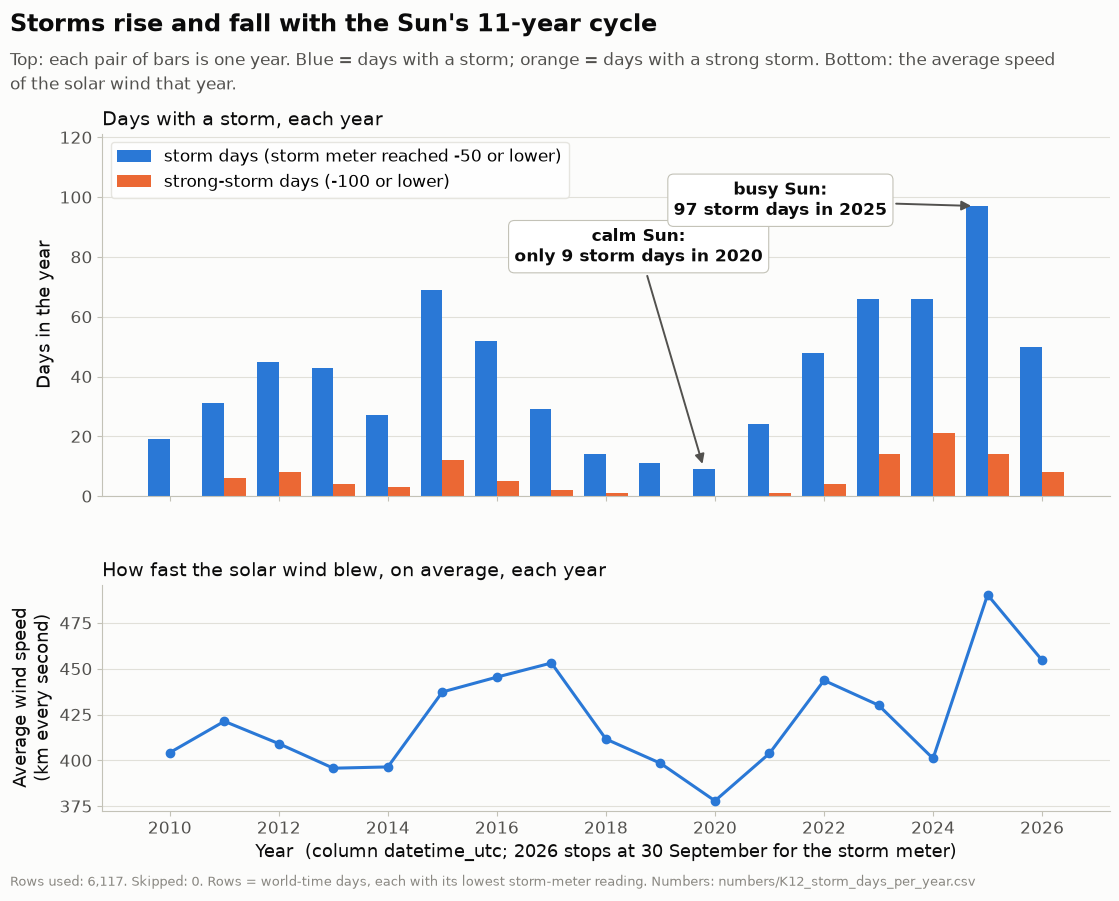

In [9]:
# K12: storm days per year (top) and the yearly average wind speed (bottom)
t12 = pd.DataFrame({"year": storm.index, "storm_days": storm.values, "strong_storm_days": strong.values,
                    "average_speed_km_s": spd.reindex(storm.index).round(1).values})
n12 = hp.save_numbers(t12, "K12_storm_days_per_year")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8.8), sharex=True, gridspec_kw={"height_ratios": [1.6, 1], "hspace": 0.3})
yy12 = t12["year"].to_numpy()
ax1.bar(yy12 - 0.2, t12["storm_days"], width=0.4, color=kc.MAIN, label="storm days (storm meter reached -50 or lower)")
ax1.bar(yy12 + 0.2, t12["strong_storm_days"], width=0.4, color=kc.HIGHLIGHT, label="strong-storm days (-100 or lower)")
kc.point_at(ax1, (2020 - 0.2, storm[2020]), f"calm Sun:\nonly {storm[2020]} storm days in 2020", (2018.6, storm.max() * 0.86))
kc.point_at(ax1, (2025 - 0.2, storm[2025]), f"busy Sun:\n{storm[2025]} storm days in 2025", (2021.2, storm.max() * 1.02))
ax1.set_ylabel("Days in the year"); kc.plain_axis(ax1, "y"); ax1.set_ylim(0, storm.max() * 1.25); ax1.grid(axis="x", visible=False)
ax1.legend(loc="upper left", frameon=True, facecolor="white", edgecolor=hp.GRID)
ax1.set_title("Days with a storm, each year", fontsize=13.5, color=hp.INK, loc="left")
ax2.plot(yy12, t12["average_speed_km_s"], color=kc.MAIN, lw=2.2, marker="o", ms=6)
ax2.set_ylabel("Average wind speed\n(km every second)"); kc.plain_axis(ax2, "y"); ax2.grid(axis="x", visible=False)
ax2.set_title("How fast the solar wind blew, on average, each year", fontsize=13.5, color=hp.INK, loc="left")
ax2.set_xlabel(f"Year  (column datetime_utc; {last_symh.year} stops at {last_symh:%d %B} for the storm meter)")
ax2.set_xticks(range(2010, 2027, 2))
kc.titles(fig, "Storms rise and fall with the Sun's 11-year cycle",
          "Top: each pair of bars is one year. Blue = days with a storm; orange = days with a strong storm. "
          "Bottom: the average speed of the solar wind that year.",
          hp.caption(int(day_min.notna().sum()), 0, "", n12, extra="Rows = world-time days, each with its lowest storm-meter reading."))
c12_ = kc.save(fig, "K12_storm_days_per_year"); plt.show()
hp.log_entry("D-K12", "Simple chart for finding 12: storm days per year and average speed", step=6, chart=c12_, numbers=n12,
             rows_used=f"{int(day_min.notna().sum()):,} days", key_numbers=[f"2020: {storm[2020]}; 2025: {storm[2025]} storm days"],
             what_it_shows="Storm days dip in 2019-2020 and climb to a peak in 2025.")

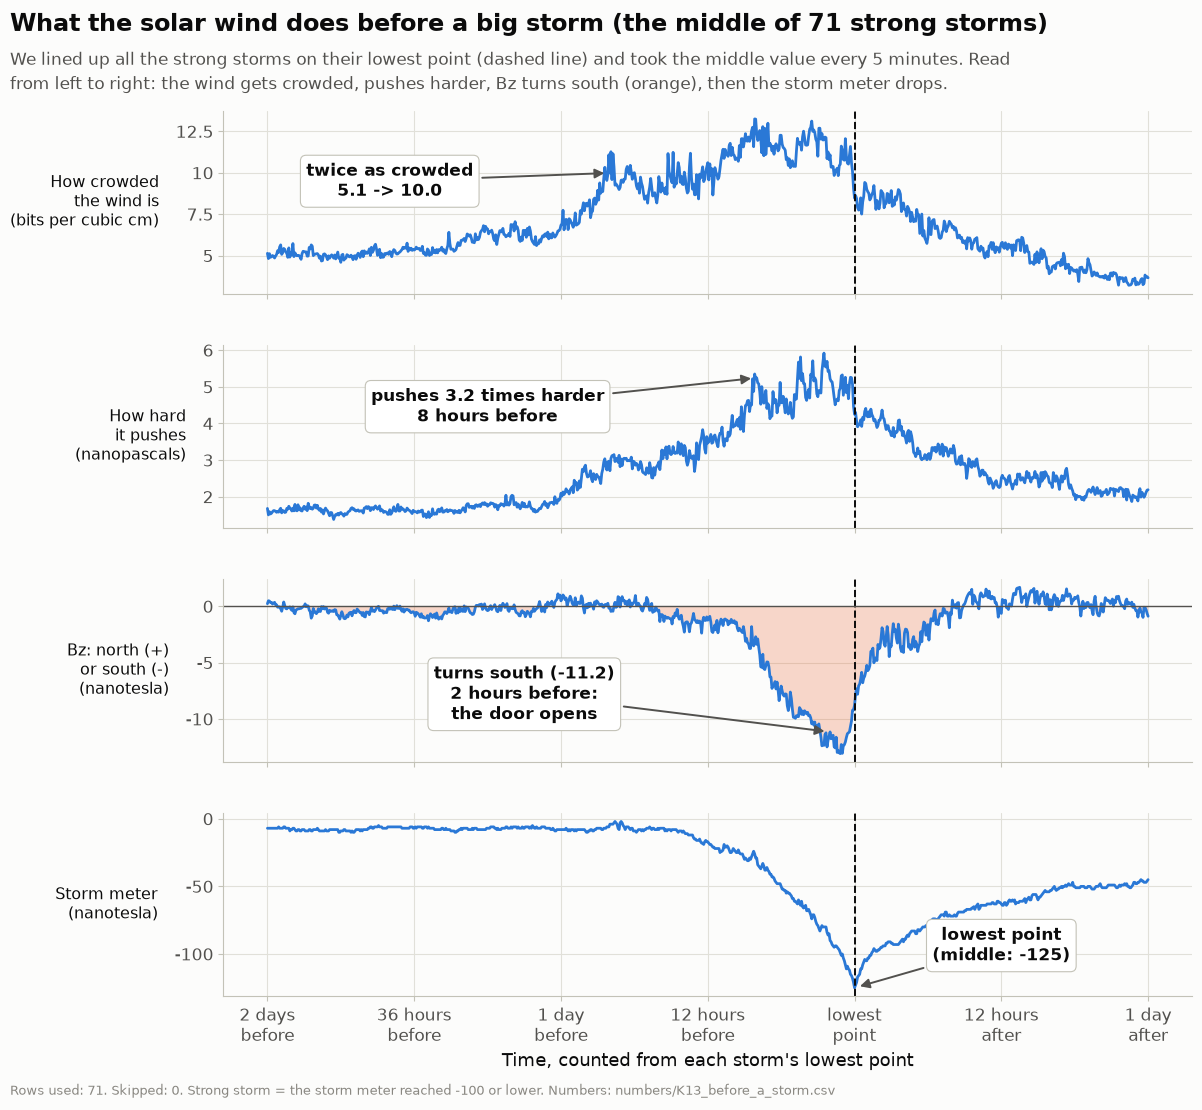

In [10]:
# K13: the middle of the strong storms, lined up on their lowest point: 4 plain panels
PAN = [("density_cm3", "How crowded\nthe wind is\n(bits per cubic cm)"), ("pressure_nPa", "How hard\nit pushes\n(nanopascals)"),
       ("bz_gsm_nT", "Bz: north (+)\nor south (-)\n(nanotesla)"), ("sym_h_nT", "Storm meter\n(nanotesla)")]
n13 = hp.save_numbers(pd.DataFrame({"hours_from_lowest": hrs, **{v: np.round(med[v], 3) for v, _ in PAN}}), "K13_before_a_storm")
fig, axs = plt.subplots(4, 1, figsize=(12.5, 11.5), sharex=True, gridspec_kw={"hspace": 0.28})
for ax, (v, lab) in zip(axs, PAN):
    ax.plot(hrs, med[v], color=kc.MAIN, lw=2)
    ax.axvline(0, color=hp.INK, lw=1.4, ls="--")
    ax.set_ylabel(lab, fontsize=11.5, rotation=0, ha="right", va="center", labelpad=12)
    kc.plain_axis(ax, "y")
axs[2].axhline(0, color=hp.INK_2, lw=1)
axs[2].fill_between(hrs, med["bz_gsm_nT"], 0, where=med["bz_gsm_nT"] < 0, color=kc.HIGHLIGHT, alpha=0.25, lw=0)
kc.point_at(axs[0], (-20, at("density_cm3", -20)), f"twice as crowded\n{d(base_den, 1)} -> {d(at('density_cm3', -20), 1)}", (-38, at("density_cm3", -20) * 0.95))
kc.point_at(axs[1], (-8, at("pressure_nPa", -8)), f"pushes {d(at('pressure_nPa', -8) / base_pre, 1)} times harder\n8 hours before",
            (-30, at("pressure_nPa", -8) * 0.85))
kc.point_at(axs[2], (-2, at("bz_gsm_nT", -2)), f"turns south ({d(at('bz_gsm_nT', -2), 1)})\n2 hours before:\nthe door opens",
            (-27, at("bz_gsm_nT", -2) * 0.7))
kc.point_at(axs[3], (0, at("sym_h_nT", 0)), f"lowest point\n(middle: {n0(at('sym_h_nT', 0))})", (12, at("sym_h_nT", 0) * 0.75))
axs[3].set_xticks([-48, -36, -24, -12, 0, 12, 24], ["2 days\nbefore", "36 hours\nbefore", "1 day\nbefore", "12 hours\nbefore",
                                                    "lowest\npoint", "12 hours\nafter", "1 day\nafter"])
axs[3].set_xlabel("Time, counted from each storm's lowest point")
kc.titles(fig, f"What the solar wind does before a big storm (the middle of {len(big)} strong storms)",
          "We lined up all the strong storms on their lowest point (dashed line) and took the middle value every 5 minutes. "
          "Read from left to right: the wind gets crowded, pushes harder, Bz turns south (orange), then the storm meter drops.",
          hp.caption(len(big), 0, "", n13, extra="Strong storm = the storm meter reached -100 or lower."))
c13_ = kc.save(fig, "K13_before_a_storm"); plt.show()
hp.log_entry("D-K13", "Simple chart for finding 13: four plain panels before a strong storm", step=6, chart=c13_, numbers=n13,
             rows_used=f"{len(big)} strong storms", key_numbers=[f"pressure x{at('pressure_nPa', -8) / base_pre:.1f} at -8 h; Bz {at('bz_gsm_nT', -2):.1f} at -2 h"],
             what_it_shows="Crowding and pushing rise first, Bz turns south, then the storm meter drops.")

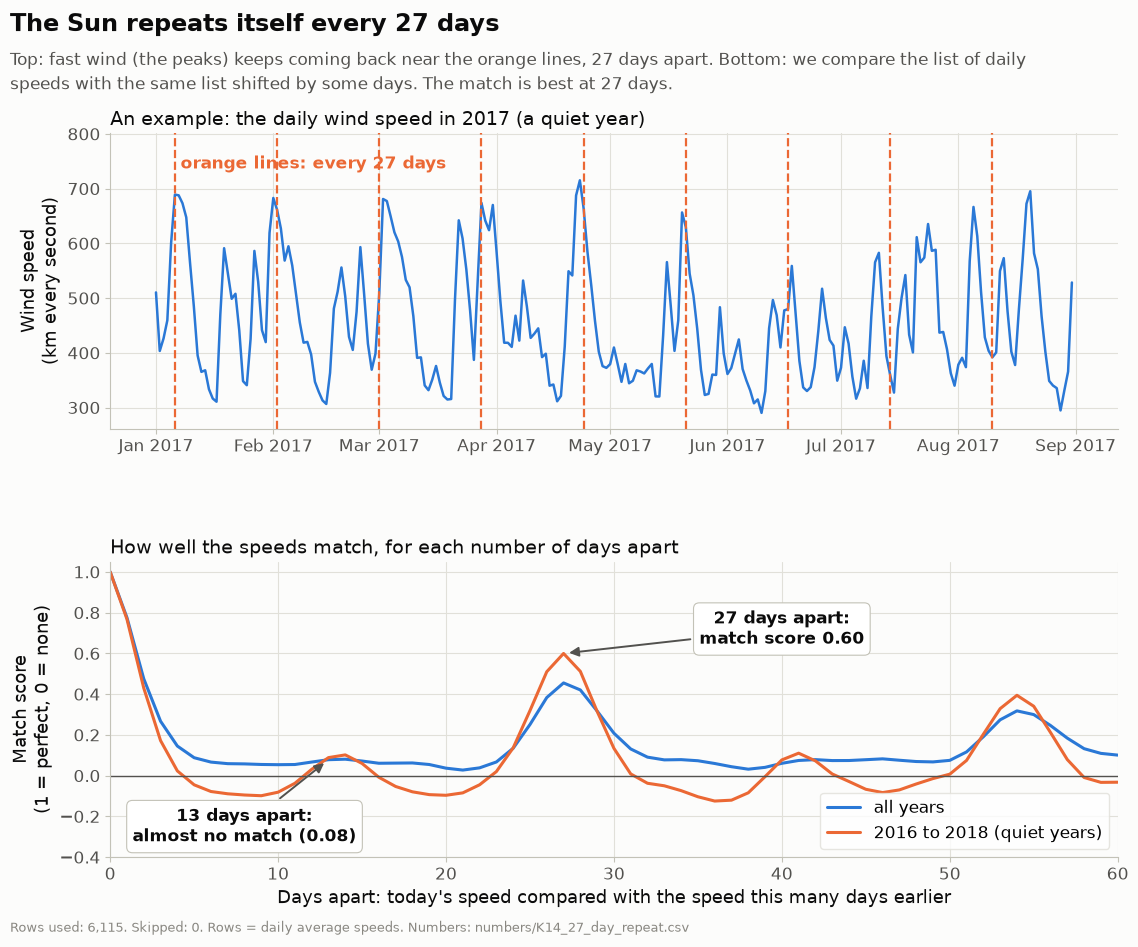

In [11]:
# K14: the fast wind comes back every 27 days: an example stretch (top) and the match score (bottom)
ex14 = dsp["2017-01-01":"2017-08-31"]
peak14 = ex14["2017-01-01":"2017-01-31"].idxmax()
t14 = pd.DataFrame({"days_apart": list(lags), "match_all_years": np.round(all_, 3), "match_2016_2018": np.round(sub_, 3)})
n14 = hp.save_numbers(t14, "K14_27_day_repeat"); hp.save_numbers(ex14.round(1).rename_axis("day").reset_index(name="speed_km_s"), "K14_27_day_repeat_2017")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9.4), gridspec_kw={"height_ratios": [1, 1], "hspace": 0.45})
ax1.plot(ex14.index, ex14.values, color=kc.MAIN, lw=1.8)
for k_ in range(0, 9):
    t_ = peak14 + pd.Timedelta(days=27 * k_)
    if t_ <= ex14.index.max():
        ax1.axvline(t_, color=kc.HIGHLIGHT, lw=1.6, ls="--")
kc.label(ax1, peak14 + pd.Timedelta(days=1.5), ex14.max() * 1.02, "orange lines: every 27 days", color=hp.SERIES[1], bold=True, va="bottom")
ax1.set_ylabel("Wind speed\n(km every second)"); kc.plain_axis(ax1, "y"); ax1.set_ylim(ex14.min() * 0.9, ex14.max() * 1.12)
ax1.set_title("An example: the daily wind speed in 2017 (a quiet year)", fontsize=13.5, color=hp.INK, loc="left")
ax1.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %Y"))
ax2.plot(list(lags), all_, color=kc.MAIN, lw=2.2, label="all years")
ax2.plot(list(lags), sub_, color=kc.HIGHLIGHT, lw=2.2, label="2016 to 2018 (quiet years)")
ax2.axhline(0, color=hp.INK_2, lw=1)
kc.point_at(ax2, (27, sub_[27]), f"27 days apart:\nmatch score {d(sub_[27], 2)}", (40, sub_[27] + 0.12))
kc.point_at(ax2, (13, all_[13]), f"13 days apart:\nalmost no match ({d(all_[13], 2)})", (8, -0.25))
ax2.set_xlabel("Days apart: today's speed compared with the speed this many days earlier")
ax2.set_ylabel("Match score\n(1 = perfect, 0 = none)"); ax2.set_xlim(0, 60); ax2.set_ylim(-0.4, 1.05)
ax2.legend(loc="lower right", frameon=True, facecolor="white", edgecolor=hp.GRID)
ax2.set_title("How well the speeds match, for each number of days apart", fontsize=13.5, color=hp.INK, loc="left")
kc.titles(fig, "The Sun repeats itself every 27 days",
          "Top: fast wind (the peaks) keeps coming back near the orange lines, 27 days apart. Bottom: we compare the list of daily "
          "speeds with the same list shifted by some days. The match is best at 27 days.",
          hp.caption(int(dsp.notna().sum()), 0, "", n14, extra="Rows = daily average speeds."))
c14_ = kc.save(fig, "K14_27_day_repeat"); plt.show()
hp.log_entry("D-K14", "Simple chart for finding 14: 27-day repeat with an example year", step=6, chart=c14_, numbers=n14,
             rows_used=f"{int(dsp.notna().sum()):,} days", key_numbers=[f"27 days: {all_[27]:.2f} (all), {sub_[27]:.2f} (2016-2018)"],
             what_it_shows="Fast-wind peaks return about every 27 days; the match score peaks at 27 days.")

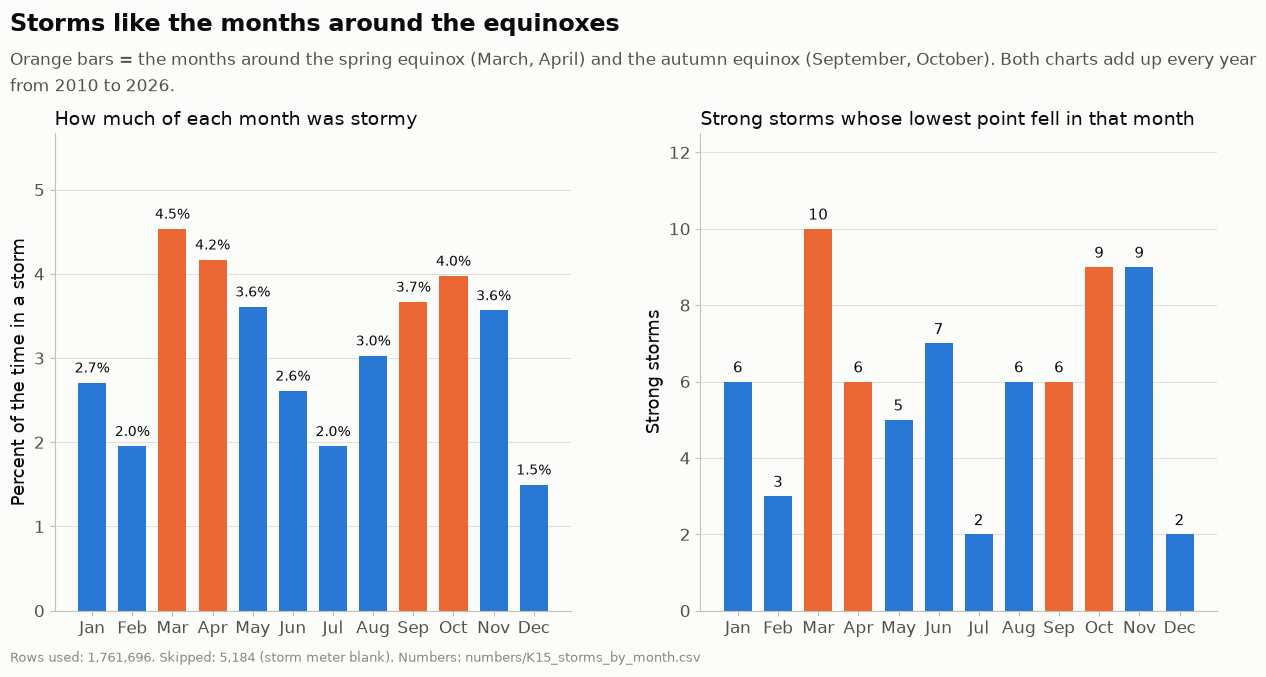

In [12]:
# K15: storms by month: share of time in a storm (left) and strong storms (right)
t15 = pd.DataFrame({"month": MON, "percent_of_time_in_storm": share.round(2).values, "strong_storms": strong_m.values})
n15 = hp.save_numbers(t15, "K15_storms_by_month")
EQX = {3, 4, 9, 10}
fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"wspace": 0.25})
axL.bar(range(12), share.values, color=[kc.HIGHLIGHT if m_ in EQX else kc.MAIN for m_ in range(1, 13)], width=0.7)
for k_, v_ in enumerate(share.values):
    kc.label(axL, k_, v_ + 0.08, p(v_, 1), ha="center", va="bottom", fontsize=10)
axL.set_xticks(range(12), MON); axL.set_ylim(0, share.max() * 1.25); axL.grid(axis="x", visible=False)
axL.set_ylabel("Percent of the time in a storm")
axL.set_title("How much of each month was stormy", fontsize=13.5, color=hp.INK, loc="left")
axR.bar(range(12), strong_m.values, color=[kc.HIGHLIGHT if m_ in EQX else kc.MAIN for m_ in range(1, 13)], width=0.7)
for k_, v_ in enumerate(strong_m.values):
    kc.label(axR, k_, v_ + 0.15, str(v_), ha="center", va="bottom", fontsize=10.5)
axR.set_xticks(range(12), MON); axR.set_ylim(0, strong_m.max() * 1.25); axR.grid(axis="x", visible=False)
axR.set_ylabel("Strong storms"); kc.plain_axis(axR, "y")
axR.set_title("Strong storms whose lowest point fell in that month", fontsize=13.5, color=hp.INK, loc="left")
kc.titles(fig, "Storms like the months around the equinoxes",
          "Orange bars = the months around the spring equinox (March, April) and the autumn equinox (September, October). "
          "Both charts add up every year from 2010 to 2026.",
          hp.caption(int(ok.sum()), int((~ok).sum()), "storm meter blank", n15))
c15_ = kc.save(fig, "K15_storms_by_month"); plt.show()
hp.log_entry("D-K15", "Simple chart for finding 15: storms by month, equinox months in orange", step=6, chart=c15_, numbers=n15,
             rows_used=int(ok.sum()), key_numbers=[f"March {share[3]:.1f}%, December {share[12]:.1f}%"],
             what_it_shows="Stormy time peaks around the equinoxes and dips in summer and winter.")

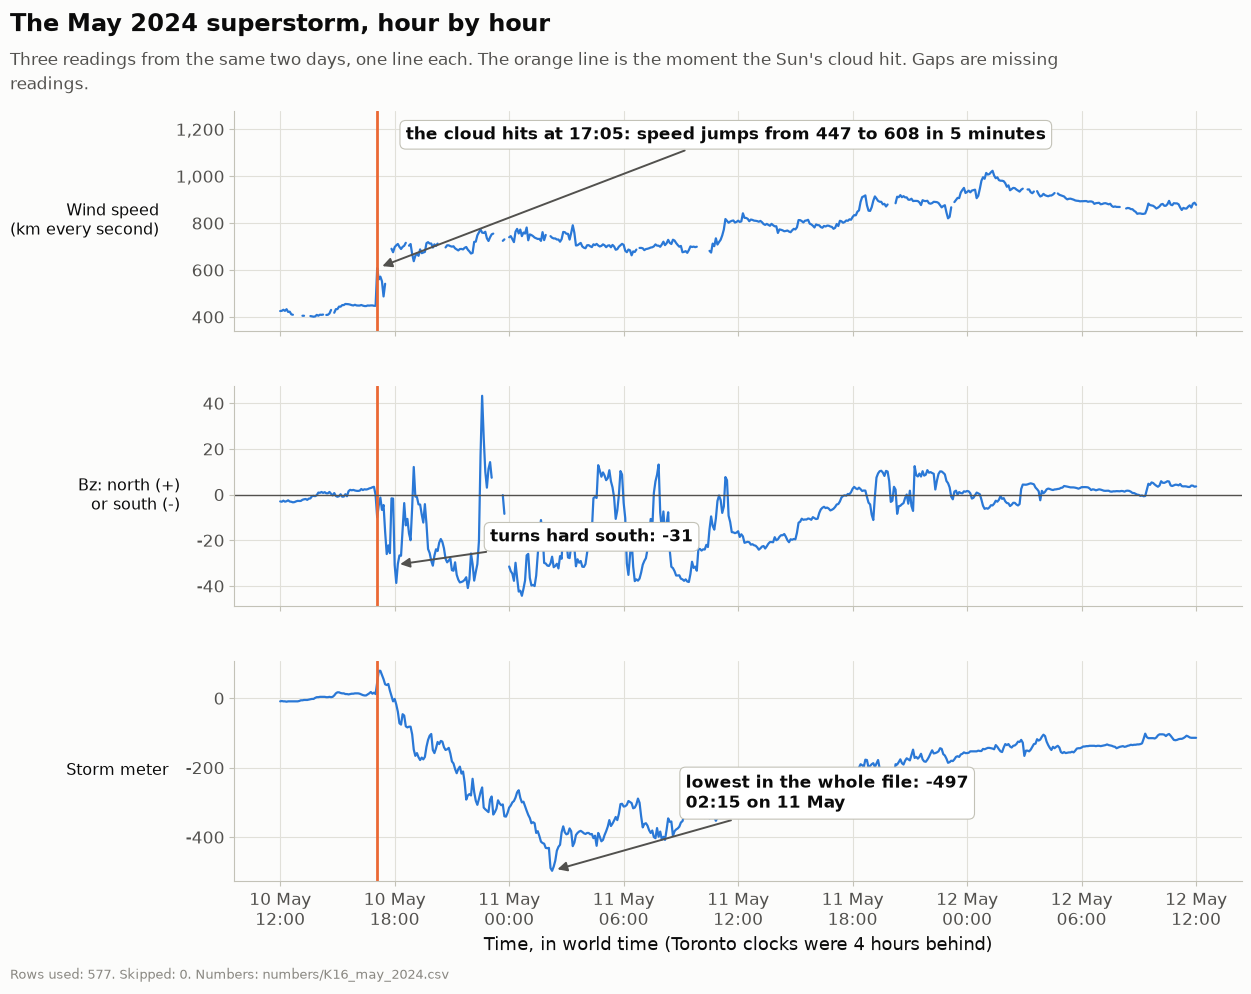

In [13]:
# K16: the May 2024 superstorm: speed, Bz and the storm meter, with the cloud's arrival marked
n16 = hp.save_numbers(w[["speed_km_s", "bz_gsm_nT", "sym_h_nT"]].reset_index(names="time_utc"), "K16_may_2024")
fig, axs = plt.subplots(3, 1, figsize=(13, 10), sharex=True, gridspec_kw={"hspace": 0.25})
for ax, v, lab in zip(axs, ["speed_km_s", "bz_gsm_nT", "sym_h_nT"],
                      ["Wind speed\n(km every second)", "Bz: north (+)\nor south (-)", "Storm meter"]):
    ax.plot(w.index, w[v], color=kc.MAIN, lw=1.6)
    ax.axvline(t_shock, color=kc.HIGHLIGHT, lw=2)
    ax.set_ylabel(lab, fontsize=11.5, rotation=0, ha="right", va="center", labelpad=12)
    kc.plain_axis(ax, "y")
axs[1].axhline(0, color=hp.INK_2, lw=1)
kc.point_at(axs[0], (t_shock, after), f"the cloud hits at {t_shock:%H:%M}: speed jumps from {n0(before)} to {n0(after)} in 5 minutes",
            (t_shock + pd.Timedelta("1.5h"), w["speed_km_s"].max() * 1.15), ha="left")
kc.point_at(axs[1], (t30, bzw[t30]), f"turns hard south: {n0(bzw[t30])}", (t30 + pd.Timedelta("5h"), bzw[t30] * 0.6), ha="left")
kc.point_at(axs[2], (low_t, low_v), f"lowest in the whole file: {n0(low_v)}\n{low_t:%H:%M} on {low_t:%d %B}",
            (low_t + pd.Timedelta("7h"), low_v * 0.55), ha="left")
axs[0].set_ylim(w["speed_km_s"].min() * 0.85, w["speed_km_s"].max() * 1.25)
axs[2].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b\n%H:%M"))
axs[2].set_xlabel("Time, in world time (Toronto clocks were 4 hours behind)")
kc.titles(fig, "The May 2024 superstorm, hour by hour",
          "Three readings from the same two days, one line each. The orange line is the moment the Sun's cloud hit. "
          "Gaps are missing readings.",
          hp.caption(len(w), 0, "", n16))
c16_ = kc.save(fig, "K16_may_2024"); plt.show()
hp.log_entry("D-K16", "Simple chart for finding 16: the May 2024 superstorm", step=6, chart=c16_, numbers=n16, rows_used=len(w),
             key_numbers=[f"cloud {t_shock:%H:%M}; speed {before:.0f}->{after:.0f}; lowest {low_v:.0f} at {low_t:%d %b %H:%M}"],
             what_it_shows="Speed jumps when the cloud hits, Bz turns south, and the storm meter falls to the file's lowest value.")

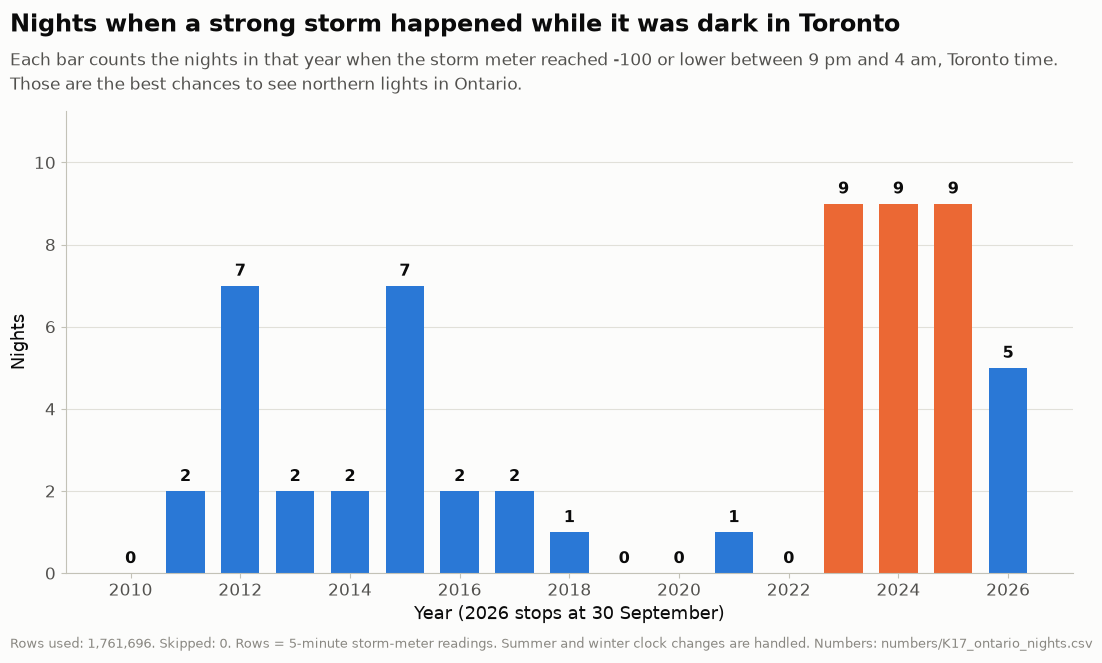

In [14]:
# K17: nights with a strong storm during Toronto's dark hours, per year
n17 = hp.save_numbers(per_y.rename_axis("year").reset_index(name="nights"), "K17_ontario_nights")
fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(per_y.index, per_y.values, color=[kc.HIGHLIGHT if v_ == per_y.max() else kc.MAIN for v_ in per_y.values], width=0.7)
for x_, v_ in per_y.items():
    kc.label(ax, x_, v_ + 0.15, str(v_), ha="center", va="bottom", fontsize=11.5, bold=True)
ax.set_xticks(range(2010, 2027, 2)); ax.set_ylim(0, per_y.max() * 1.25)
ax.set_xlabel(f"Year ({last_symh.year} stops at {last_symh:%d %B})"); ax.set_ylabel("Nights"); kc.plain_axis(ax, "y")
ax.grid(axis="x", visible=False)
kc.titles(fig, "Nights when a strong storm happened while it was dark in Toronto",
          "Each bar counts the nights in that year when the storm meter reached -100 or lower between 9 pm and 4 am, "
          "Toronto time. Those are the best chances to see northern lights in Ontario.",
          hp.caption(len(s), 0, "", n17, extra="Rows = 5-minute storm-meter readings. Summer and winter clock changes are handled."))
c17_ = kc.save(fig, "K17_ontario_nights"); plt.show()
hp.log_entry("D-K17", "Simple chart for finding 17: strong-storm nights in Toronto's dark hours", step=6, chart=c17_, numbers=n17,
             rows_used=len(s), key_numbers=[f"{len(good)} nights"], what_it_shows="Strong-storm nights cluster in 2023-2025.")